# `a + b` の計算時間と桁数

Python では 2 数の和を `x = a + b` と 1 命令で書けるが，
実行時間は常に一定ではない。

- `a`, `b` が小さいとき … ほぼ一定
- `a`, `b` が大きいとき … 桁数に比例して増加

Python の整数は桁数に上限がないので，大きな数では内部で多倍長の加算がおこなわれる。
**「1 命令」と「1 ステップ」は同じではない**という，第1回の論点そのものである。

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

In [2]:
import random
import timeit
import sys

import numpy as np

print("準備ができた")

準備ができた


## 計測

ある桁数 `bits` の乱数 `a`, `b` を作り，`a + b` を `number` 回繰り返して
1 回あたりの時間を求める。これを `repeats` 回おこなって散布図の 1 列ぶんとする。

`timeit` の測る時間には繰り返しそのものの手間も含まれる。
小さい数でも 0 にならず 100 ns 前後で頭打ちになるのはそのためである。
知りたいのは絶対値ではなく **桁数に対する増え方** なので，これで差し支えない。

In [3]:
def measure_ns(bits, number=20000):
    """bits 桁の 2 数の和 1 回あたりの時間（ナノ秒）を測る。"""
    a = random.getrandbits(bits)
    b = random.getrandbits(bits)
    timer = timeit.Timer("a + b", globals={"a": a, "b": b})
    return timer.timeit(number) / number * 1e9


def collect(bit_values, repeats=20, number=20000):
    """各桁数について repeats 回測り、(桁数, 時間) の組を返す。"""
    xs, ys = [], []
    for bits in bit_values:
        for _ in range(repeats):
            xs.append(bits)
            ys.append(measure_ns(bits, number))
    return np.array(xs), np.array(ys)

In [4]:
# 試しに 1 点だけ測ってみる
print(f"{measure_ns(32):.1f} ns   (32 bit)")
print(f"{measure_ns(10000):.1f} ns   (10000 bit)")

25.7 ns   (32 bit)
431.7 ns   (10000 bit)


## 3 つのレンジで測る

同じ現象でも，横軸の範囲を変えると見え方が変わる。
狭い範囲では平らに見えるものが，広げると比例して増えていることが分かる。

In [5]:
ranges = [
    ("0〜50 bit",     range(1, 51)),
    ("0〜400 bit",    range(1, 401, 8)),
    ("0〜10000 bit",  range(1, 10001, 200)),
]

data = []
for label, bit_values in ranges:
    xs, ys = collect(list(bit_values))
    data.append((label, xs, ys))
    print(f"{label}: {len(xs)} 点  中央値 {np.median(ys):.0f} ns")

0〜50 bit: 1000 点  中央値 23 ns


0〜400 bit: 1000 点  中央値 31 ns


0〜10000 bit: 1000 点  中央値 196 ns


## 描画

スライドと同じく 3 枚を横に並べる。
点が重なるので透明度を下げ，散らばりが見えるようにする。

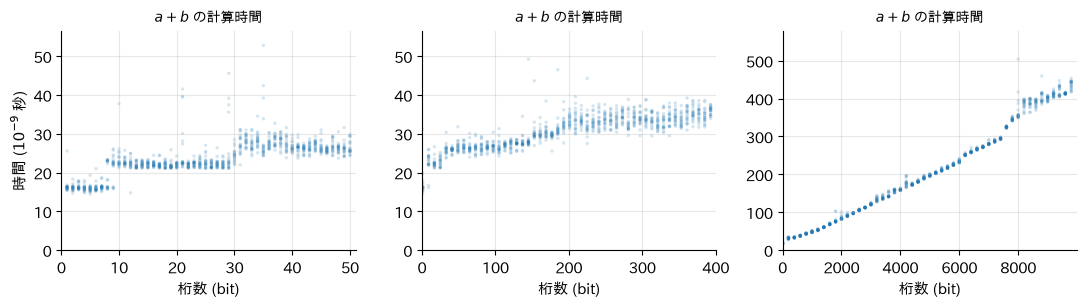

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.2))

# 左と中は縦軸をそろえる。そうすると左が「ほぼ一定」に見える
# （スライドと同じ枠取り）
ymax_left = data[1][2].max() * 1.15

for i, (ax, (label, xs, ys)) in enumerate(zip(axes, data)):
    ax.scatter(xs, ys, s=6, alpha=0.18, edgecolors="none")
    ax.set_title("$a + b$ の計算時間", fontsize=10)
    ax.set_xlabel("桁数 (bit)")
    ax.set_xlim(0, xs.max() * 1.02)
    ax.set_ylim(0, ymax_left if i < 2 else ys.max() * 1.15)

axes[0].set_ylabel("時間 ($10^{-9}$ 秒)")
fig.tight_layout()

## 読み取れること

- 左（〜50 bit）では平らに見える。小さい数の加算は 1 ステップと数えてよい
- 中（〜400 bit）でわずかに右上がりになる
- 右（〜10000 bit）でははっきり比例して増える

つまり `a + b` を 1 ステップと数えてよいかどうかは，扱う数の大きさによる。
**計算モデルを決めないとステップ数は数えられない**ということである。

本講義では，扱う数は計算機の 1 語に収まるものとし，
四則演算・比較・代入をいずれも 1 ステップと数えることにしている。

## おまけ：左の図を拡大すると階段が見える

縦軸をそろえると平らに見えるが，左の範囲だけを拡大すると
**段差**がいくつか現れる。これは測定の誤差ではなく，
CPython が整数をどう持っているかが表に出たものである。

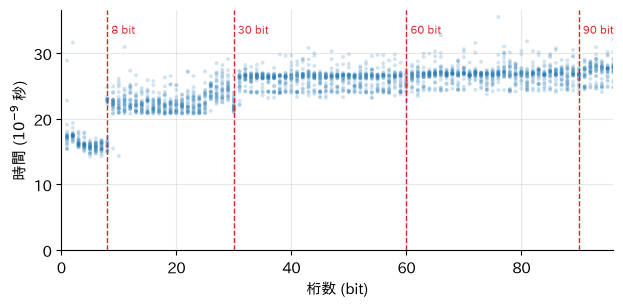

In [7]:
xs, ys = collect(list(range(1, 97)), repeats=25)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.scatter(xs, ys, s=8, alpha=0.2, edgecolors="none")
for boundary in (8, 30, 60, 90):
    ax.axvline(boundary, color="#d62728", lw=1.0, ls="--")
    ax.text(boundary + 0.7, ys.max() * 0.97, f"{boundary} bit",
            fontsize=8, color="#d62728", va="top")
ax.set_xlabel("桁数 (bit)")
ax.set_ylabel("時間 ($10^{-9}$ 秒)")
ax.set_xlim(0, 96)
ax.set_ylim(0, None)
fig.tight_layout()

段差の位置は，次の 2 つで説明がつく。確かめてみよう。

In [8]:
import sys

print(sys.int_info)

# 小さい整数はあらかじめ作り置きされ、使い回される
for v in (256, 257):
    print(v, "は作り置き:", int(str(v)) is v)

sys.int_info(bits_per_digit=30, sizeof_digit=4, default_max_str_digits=4300, str_digits_check_threshold=640)
256 は作り置き: True
257 は作り置き: False


- **8 bit 付近**（はっきり見える）… CPython は $-5$ から $256$ までの整数を
  作り置きして使い回す。`getrandbits(9)` は 511 までの値を返すので，
  この範囲を超えはじめる。作る手間のぶんだけ時間が増える
- **30 bit 付近**（はっきり見える）… CPython は多倍長整数を 30 bit ずつの
  「桁」に分けて持つ（`bits_per_digit=30`）。30 bit を超えると 1 桁から 2 桁になる
- **60 bit・90 bit 付近**（ほとんど見えない）… 同じ理由で 3 桁，4 桁になる境目だが，
  1 桁ぶんの手間は固定の手間に比べてごく小さいので，段差としては埋もれる

3 つめは，右の図（〜10000 bit）のように桁数を大きく変えて
はじめて目に見えるようになる。

つまり「$a+b$ は 1 ステップ」という見方は，
**実装の都合に支えられた近似** にすぎない。
どこまでを 1 ステップと見なすかは，何を論じたいかによって決める。

## おまけ 2：右の図の段差は何か

右の図（〜10000 bit）をよく見ると，3800 bit や 7500 bit のあたりで
時間が段状に跳ね上がっている。桁数に比例して増えるだけなら，こうはならない。

まず，**加算が原因なのかどうか**を切り分ける。
`-a`（符号を変えるだけ）は桁を写すが，加算の計算はほとんどしない。
これで同じ段差が出るなら，原因は加算ではない。

In [9]:
def t_expr(expr, bits, number=20000, best_of=3):
    a = random.getrandbits(bits)
    b = random.getrandbits(bits)
    return min(timeit.Timer(expr, globals={"a": a, "b": b}).timeit(number) / number * 1e9
               for _ in range(best_of))


print("桁数    a + b      -a    （ns）")
for bits in (3500, 3800, 5900, 6100, 7400, 7600):
    print(f"{bits:5d}  {t_expr('a + b', bits):7.1f} {t_expr('-a', bits):7.1f}")

桁数    a + b      -a    （ns）
 3500    183.7    39.6
 3800    200.8    50.4
 5900    287.6    50.2
 6100    267.4    51.4
 7400    318.9    50.4
 7600    410.7   126.2


`-a` でも同じ位置で跳ねる。しかも絶対値はずっと小さい。
つまり段差は **加算の手間ではなく，結果を入れる領域を確保する手間** から来ている。

では境目はどこか。オブジェクトの大きさと並べてみる。

In [10]:
print("桁数   sizeof   -a (ns)")
prev = None
for bits in range(3600, 3721, 10):
    size = sys.getsizeof(random.getrandbits(bits))
    mark = "  ← 512 バイトを超える" if prev is not None and prev <= 512 < size else ""
    prev = size
    print(f"{bits:5d}  {size:6d}  {t_expr('-a', bits, number=40000, best_of=5):7.1f}{mark}")

桁数   sizeof   -a (ns)
 3600     504     39.2
 3610     508     39.3
 3620     508     39.7
 3630     508     39.9
 3640     512     39.8
 3650     512     39.2
 3660     512     39.5


 3670     516     50.4  ← 512 バイトを超える
 3680     516     50.7


 3690     516     50.7
 3700     520     51.1
 3710     520     51.2
 3720     520     50.5


`sys.getsizeof` が 512 バイトを超えた，まさにその桁数で跳ねている。

CPython は **512 バイト以下の小さな確保を自前のアロケータでまかない**，
それを超えるとシステムの `malloc` を呼ぶ。この切り替わりが段差の正体である。

- **3650 bit 付近（512 バイト）** … 自前のアロケータからシステムの `malloc` へ
- **7500 bit 付近（1024 バイト）** … `malloc` 側でも区分が変わる境目と一致する
- **6000 bit 付近** … より小さな段差。こちらは境界を特定できていない

### この実験から言えること {.unnumbered}

測ったのは「2 数の和を求める時間」のつもりだったが，
実際には **領域を確保する時間も一緒に測っていた**。

アルゴリズムの計算量を論じるときに計算モデルを先に決めるのは，
こうした「測りたかったもの以外」を議論から切り離すためでもある。
実測は多くを教えてくれるが，何を測っているのかは自分で見極める必要がある。